# K-Means

Split unlabeled points into `k` groups so that points in a group are close to the group's centre. Formally, minimise the **inertia**

$$\sum_{j=1}^{k} \sum_{x \in C_j} \lVert x - \mu_j \rVert^2$$

**Lloyd's algorithm** alternates two steps; each one can only lower the inertia, so it always converges (to a *local* minimum):

1. **Assign** every point to its nearest centroid.
2. **Update** every centroid to the mean of its points.

Starting positions matter, so the first centroids are chosen with **k-means++**: pick one point at random, then pick each further centroid with probability proportional to its squared distance from the nearest centroid already chosen. That spreads the starts out.

This notebook is self-contained: implementation, visuals, scikit-learn check and tests.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

`fit` runs Lloyd's loop until the centroids move less than `tol`. `n_iters` caps the loop, which the visuals below use to freeze the algorithm after 0, 1, 2… iterations.

In [2]:
import numpy as np


class KMeans:
    """Lloyd's algorithm with k-means++ initialization."""

    def __init__(self, n_clusters=3, n_iters=300, tol=1e-4, random_state=0):
        self.n_clusters = n_clusters
        self.n_iters = n_iters
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None
        self.inertia_ = None

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        rng = np.random.default_rng(self.random_state)
        self.centroids = self._kmeans_plusplus_init(X, rng)

        for _ in range(self.n_iters):
            labels = self._assign(X)
            new_centroids = np.array(
                [
                    X[labels == k].mean(axis=0) if np.any(labels == k) else self.centroids[k]
                    for k in range(self.n_clusters)
                ]
            )
            shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids
            if shift < self.tol:
                break

        self.labels_ = self._assign(X)
        self.inertia_ = self._inertia(X, self.labels_)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self._assign(X)

    def _assign(self, X):
        dists = np.linalg.norm(X[:, None, :] - self.centroids[None, :, :], axis=2)
        return np.argmin(dists, axis=1)

    def _inertia(self, X, labels):
        return sum(
            np.sum((X[labels == k] - self.centroids[k]) ** 2) for k in range(self.n_clusters)
        )

    def _kmeans_plusplus_init(self, X, rng):
        n_samples = X.shape[0]
        centroids = [X[rng.integers(n_samples)]]
        for _ in range(1, self.n_clusters):
            dists = np.min(
                [np.sum((X - c) ** 2, axis=1) for c in centroids], axis=0
            )
            probs = dists / dists.sum()
            next_idx = rng.choice(n_samples, p=probs)
            centroids.append(X[next_idx])
        return np.array(centroids)

## See it work

### 1. The algorithm, iteration by iteration

Four overlapping blobs. With `n_iters = 0` the centroids are just the k-means++ starting points (red crosses). Each extra iteration assigns points, then moves the centroids to the means. Inertia falls and then stops changing.

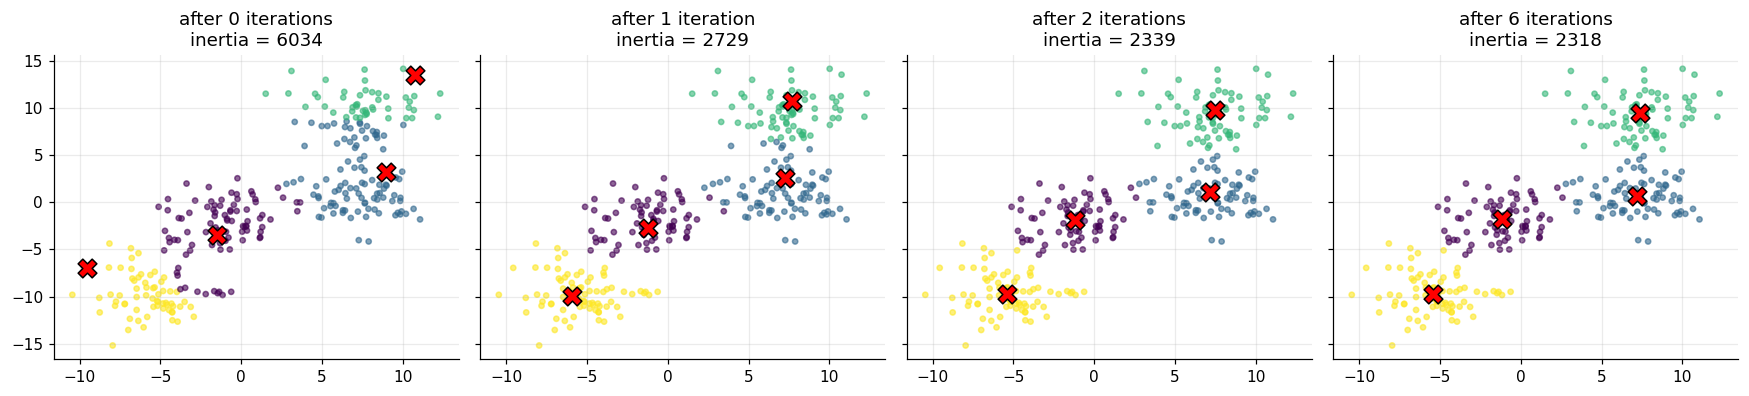

In [3]:
from sklearn.datasets import make_blobs

Xi, _ = make_blobs(n_samples=300, centers=4, cluster_std=1.9, random_state=8)   # overlapping blobs: takes a few iterations

fig, axes = plt.subplots(1, 4, figsize=(16, 3.7), sharex=True, sharey=True)
for ax, k in zip(axes, [0, 1, 2, 6]):
    m = KMeans(n_clusters=4, n_iters=k, random_state=7).fit(Xi)
    ax.scatter(*Xi.T, c=m.labels_, cmap="viridis", s=12, alpha=0.6)
    ax.scatter(*m.centroids.T, c="red", marker="X", s=150, edgecolor="k", zorder=3)
    ax.set_title(f"after {k} iteration{'s' if k != 1 else ''}\ninertia = {m.inertia_:.0f}")
plt.tight_layout(); plt.show()

### 2. What the model has learned: regions

Every point of the plane belongs to its nearest centroid, so the model carves space into straight-edged (Voronoi) regions. `predict` is exactly this lookup, which is how new points get a label.

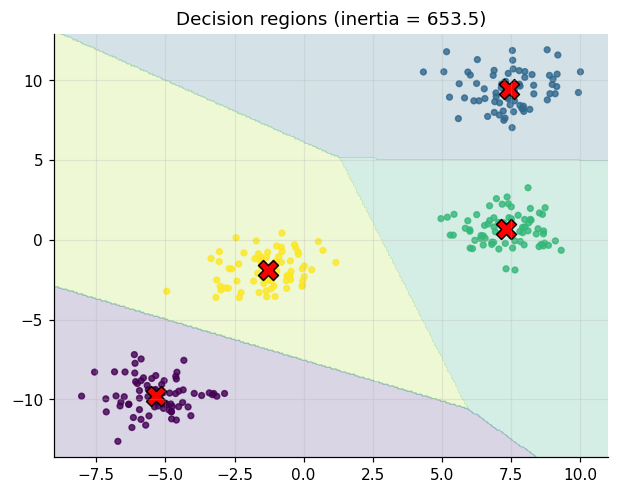

In [4]:
X, _ = make_blobs(n_samples=300, centers=4, cluster_std=1.0, random_state=8)
m = KMeans(n_clusters=4, random_state=0).fit(X)
gx, gy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 300), np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 300))
regions = m.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)

plt.figure(figsize=(6.5, 5))
plt.contourf(gx, gy, regions, alpha=0.2, cmap="viridis", levels=np.arange(-0.5, 4))
plt.scatter(*X.T, c=m.labels_, cmap="viridis", s=14, alpha=0.8)
plt.scatter(*m.centroids.T, c="red", marker="X", s=170, edgecolor="k")
plt.title(f"Decision regions (inertia = {m.inertia_:.1f})"); plt.show()

### 3. Choosing `k`: the elbow

Inertia always drops as `k` grows (more centres means shorter distances), so you cannot just minimise it. Look for the **elbow**: the `k` after which extra clusters stop paying off. Here the data really has 4 blobs.

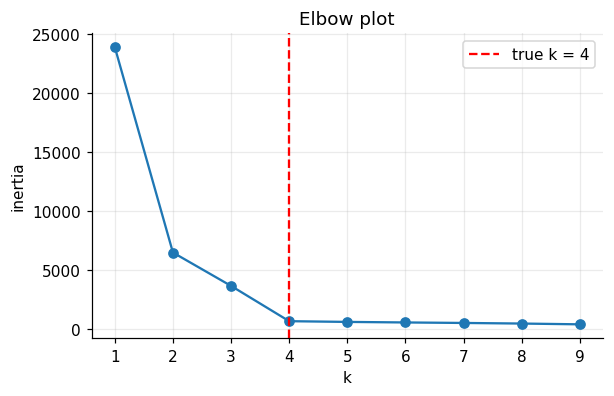

In [5]:
ks = range(1, 10)
inertias = [KMeans(n_clusters=k, random_state=0).fit(X).inertia_ for k in ks]
plt.figure(figsize=(6, 3.6))
plt.plot(list(ks), inertias, "o-"); plt.axvline(4, color="r", ls="--", label="true k = 4")
plt.xlabel("k"); plt.ylabel("inertia"); plt.title("Elbow plot"); plt.legend(); plt.show()

### 4. Initialisation matters: restart and keep the best

Lloyd's algorithm finds a *local* optimum. On messier data, different seeds give different answers. The standard fix is to run several seeds and keep the lowest inertia (scikit-learn's `n_init`).

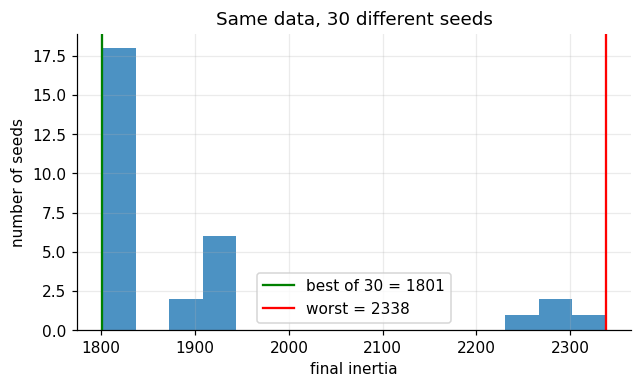

In [6]:
Xh, _ = make_blobs(n_samples=400, centers=7, cluster_std=1.6, random_state=11)
scores = np.array([KMeans(n_clusters=7, random_state=s).fit(Xh).inertia_ for s in range(30)])
plt.figure(figsize=(6.5, 3.5))
plt.hist(scores, bins=15, color="C0", alpha=0.8)
plt.axvline(scores.min(), color="g", label=f"best of 30 = {scores.min():.0f}")
plt.axvline(scores.max(), color="r", label=f"worst = {scores.max():.0f}")
plt.xlabel("final inertia"); plt.ylabel("number of seeds"); plt.title("Same data, 30 different seeds"); plt.legend(); plt.show()

### 5. Where K-Means fails

K-Means assumes **round, similar-sized** clusters, because it uses distance to a centre. Curved or stretched shapes get cut in the wrong place. For those see `29_gaussian_mixture` (elliptical) and `33_spectral_clustering` / `32_dbscan` (arbitrary shapes).

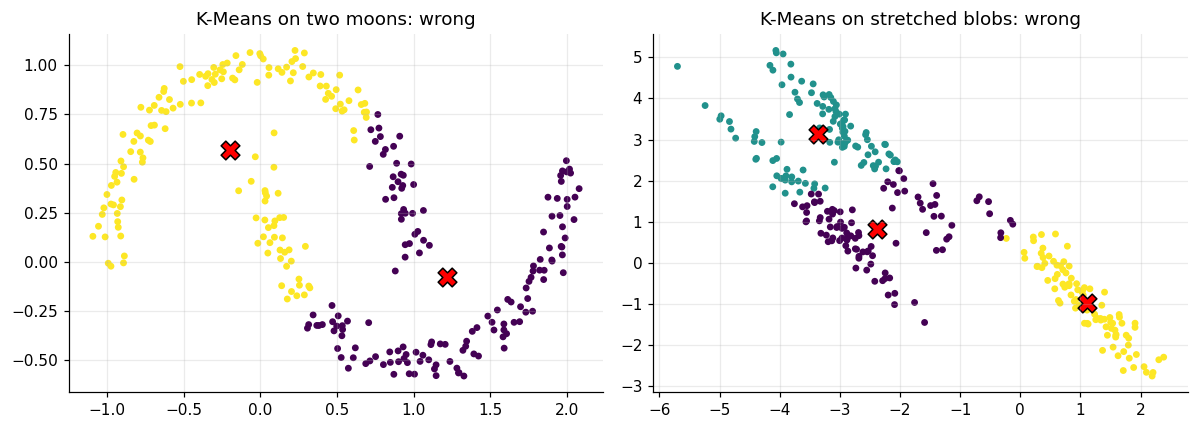

In [7]:
from sklearn.datasets import make_moons

Xm, _ = make_moons(n_samples=300, noise=0.06, random_state=1)
Xa, _ = make_blobs(n_samples=300, centers=3, random_state=170)
Xa = Xa @ np.array([[0.6, -0.64], [-0.4, 0.85]])      # stretch the blobs into ellipses

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, data, k, title in [(axes[0], Xm, 2, "two moons"), (axes[1], Xa, 3, "stretched blobs")]:
    m = KMeans(n_clusters=k, random_state=0).fit(data)
    ax.scatter(*data.T, c=m.labels_, cmap="viridis", s=12)
    ax.scatter(*m.centroids.T, c="red", marker="X", s=150, edgecolor="k")
    ax.set_title(f"K-Means on {title}: wrong")
plt.tight_layout(); plt.show()

## Check against scikit-learn

K-Means is sensitive to the start, so we compare a single run of ours to scikit-learn's best of 10: ours should land close.

In [8]:
from sklearn.cluster import KMeans as SklearnKMeans

X4, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.8, random_state=42)
ours = KMeans(n_clusters=4, random_state=0).fit(X4)
theirs = SklearnKMeans(n_clusters=4, n_init=10, random_state=0).fit(X4)
print("inertia: ours=%.4f sklearn=%.4f" % (ours.inertia_, theirs.inertia_))
assert ours.inertia_ < theirs.inertia_ * 1.5
print("close to scikit-learn's best-of-10")

inertia: ours=362.4724 sklearn=362.4724
close to scikit-learn's best-of-10


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [9]:
import numpy as np


def test_three_separated_blobs():
    rng = np.random.default_rng(0)
    blob0 = rng.normal(loc=[0, 0], scale=0.3, size=(50, 2))
    blob1 = rng.normal(loc=[10, 10], scale=0.3, size=(50, 2))
    blob2 = rng.normal(loc=[0, 10], scale=0.3, size=(50, 2))
    X = np.vstack([blob0, blob1, blob2])

    model = KMeans(n_clusters=3, random_state=1).fit(X)

    # each true blob should map to exactly one cluster label (up to permutation)
    labels_per_blob = [
        set(model.labels_[0:50]),
        set(model.labels_[50:100]),
        set(model.labels_[100:150]),
    ]
    for labels in labels_per_blob:
        assert len(labels) == 1
    assert len({frozenset(s) for s in labels_per_blob}) == 3  # 3 distinct clusters used


def test_inertia_decreases_with_more_clusters():
    rng = np.random.default_rng(0)
    X = rng.normal(size=(100, 2))
    inertia_1 = KMeans(n_clusters=1, random_state=0).fit(X).inertia_
    inertia_5 = KMeans(n_clusters=5, random_state=0).fit(X).inertia_
    assert inertia_5 < inertia_1

In [10]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_three_separated_blobs
PASS test_inertia_decreases_with_more_clusters

all 2 tests passed


## Takeaways

- **Use it when** clusters are compact and roughly spherical, you know (or can estimate) `k`, and you need something fast. `O(n·k·d)` per iteration.
- **Assumptions:** round clusters of similar size and density; features on comparable scales (**standardise first**, distance is the whole algorithm).
- **Pitfalls:** local optima (restart), outliers drag centroids (see `28_kmedoids`), must choose `k`, fails on non-convex shapes (section 5).
- **Interview line:** *"Assign to the nearest centroid, set each centroid to its cluster mean; inertia never increases, so it converges to a local optimum. Use k-means++ and several restarts."*